## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027神经活动轨迹数据审计.py', 'logs/audit_data/initial/summary.json')
run_long_task('261027视频神经帧同步恢复.py', 'logs/recover_video_sync/initial/summary.json')
run_long_task('261027视频特征提取与对齐.py', 'logs/extract_align_video/initial/aligned_video_features.csv')


复用： logs/audit_data/initial/summary.json
复用： logs/recover_video_sync/initial/summary.json
复用： logs/extract_align_video/initial/aligned_video_features.csv


### notebook 内部短计算：regional_event_propagation


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import detrend, find_peaks

def make_segments(labels: np.ndarray) -> pd.DataFrame:
    changes = np.r_[True, labels[1:] != labels[:-1], True]
    boundaries = np.flatnonzero(changes)
    return pd.DataFrame([{'start': int(a), 'stop': int(b), 'state': str(labels[a])} for a, b in zip(boundaries[:-1], boundaries[1:], strict=True)])

def episode_detrend(values: np.ndarray, segments: pd.DataFrame) -> np.ndarray:
    output = np.empty_like(values)
    for row in segments.itertuples(index=False):
        output[row.start:row.stop] = detrend(values[row.start:row.stop], axis=0, type='linear')
    return output

def detect_events(score: np.ndarray, table: pd.DataFrame, half_window: int, distance: int, quantile: float) -> tuple[np.ndarray, np.ndarray]:
    threshold = float(np.quantile(score[np.concatenate([np.arange(row.start, row.stop) for row in table.itertuples(index=False)])], quantile))
    events, episode_ids = ([], [])
    for episode_id, row in enumerate(table.itertuples(index=False)):
        block = score[row.start:row.stop]
        peaks, _ = find_peaks(block, height=threshold, distance=distance)
        peaks = peaks[(peaks >= half_window) & (peaks < len(block) - half_window)]
        events.extend(row.start + peaks)
        episode_ids.extend([episode_id] * len(peaks))
    return (np.asarray(events, dtype=int), np.asarray(episode_ids, dtype=int))

def event_tensor(values: np.ndarray, events: np.ndarray, half_window: int) -> np.ndarray:
    offsets = np.arange(-half_window, half_window + 1)
    return np.stack([values[event + offsets] for event in events])

def peak_lags(template: np.ndarray, half_window: int, sampling_hz: float) -> np.ndarray:
    return (np.argmax(template, axis=0) - half_window) / sampling_hz


In [3]:
from types import SimpleNamespace

regional_event_propagation_sentinel = PROJECT_ROOT / 'logs/regional_event_propagation/initial/summary.json'
if FORCE_RECOMPUTE or not regional_event_propagation_sentinel.exists():
    args = SimpleNamespace(audit_dir=PROJECT_ROOT / 'logs/audit_data/initial', output_dir=PROJECT_ROOT / 'logs/regional_event_propagation/initial', state='NREM', sampling_hz=4.146313525439001, window_seconds=3.0, minimum_distance_seconds=3.0, threshold_quantile=0.9, bootstrap_replicates=500, seed=20261009)
    args.output_dir.mkdir(parents=True, exist_ok=True)
    archive = np.load(args.audit_dir / 'region_means.npz', allow_pickle=True)
    raw, labels, region_names = (archive['values'].astype(np.float64), archive['labels'].astype(str), archive['regions'].astype(str))
    segments = make_segments(labels)
    state_segments = segments[segments.state == args.state].reset_index(drop=True)
    values = episode_detrend(raw, segments)
    state_index = np.concatenate([np.arange(row.start, row.stop) for row in state_segments.itertuples(index=False)])
    mean, std = (values[state_index].mean(axis=0), values[state_index].std(axis=0))
    z = (values - mean) / np.where(std > 0, std, 1.0)
    score = z.mean(axis=1)
    half_window = int(round(args.window_seconds * args.sampling_hz))
    distance = int(round(args.minimum_distance_seconds * args.sampling_hz))
    events, episode_ids = detect_events(score, state_segments, half_window, distance, args.threshold_quantile)
    tensor = event_tensor(z, events, half_window)
    template = tensor.mean(axis=0)
    lags = peak_lags(template, half_window, args.sampling_hz)
    rng = np.random.default_rng(args.seed)
    bootstrap_lags = np.empty((args.bootstrap_replicates, len(region_names)))
    split_correlations = []
    for replicate in range(args.bootstrap_replicates):
        sample = rng.integers(0, len(events), size=len(events))
        bootstrap_lags[replicate] = peak_lags(tensor[sample].mean(axis=0), half_window, args.sampling_hz)
        permutation = rng.permutation(len(events))
        midpoint = len(events) // 2
        first = peak_lags(tensor[permutation[:midpoint]].mean(axis=0), half_window, args.sampling_hz)
        second = peak_lags(tensor[permutation[midpoint:]].mean(axis=0), half_window, args.sampling_hz)
        split_correlations.append(np.corrcoef(first, second)[0, 1])
    lag_table = pd.DataFrame({'region': region_names, 'peak_lag_seconds': lags, 'bootstrap_median_seconds': np.median(bootstrap_lags, axis=0), 'bootstrap_q025_seconds': np.quantile(bootstrap_lags, 0.025, axis=0), 'bootstrap_q975_seconds': np.quantile(bootstrap_lags, 0.975, axis=0)})
    lag_table.sort_values('peak_lag_seconds').to_csv(args.output_dir / 'regional_peak_lags.csv', index=False)
    offsets = np.arange(-half_window, half_window + 1) / args.sampling_hz
    np.savez_compressed(args.output_dir / 'event_templates.npz', template=template, offsets_seconds=offsets, event_indices=events, episode_ids=episode_ids, bootstrap_lags=bootstrap_lags, region_names=region_names)
    summary = {'state': args.state, 'n_events': int(len(events)), 'n_episodes_with_events': int(len(np.unique(episode_ids))), 'n_state_episodes': int(len(state_segments)), 'threshold_quantile': args.threshold_quantile, 'event_score_threshold': float(np.quantile(score[state_index], args.threshold_quantile)), 'median_split_half_lag_correlation': float(np.nanmedian(split_correlations)), 'split_half_lag_correlation_q025_q975': [float(np.nanquantile(split_correlations, 0.025)), float(np.nanquantile(split_correlations, 0.975))], 'regions_with_bootstrap_interval_excluding_zero': int(np.sum((lag_table.bootstrap_q025_seconds > 0) | (lag_table.bootstrap_q975_seconds < 0)))}
    (args.output_dir / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
    print(json.dumps(summary, indent=2))
    print(lag_table.sort_values('peak_lag_seconds').to_string(index=False))
else:
    print('复用：', regional_event_propagation_sentinel.relative_to(PROJECT_ROOT))


复用： logs/regional_event_propagation/initial/summary.json


### notebook 内部短计算：regional_video_exogenous


In [4]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
STATES = ('Awake', 'NREM', 'REM')
VIDEO_COLUMNS = ('face_motion', 'eye_mean', 'eye_std', 'eye_dark_fraction')
MODELS = ('zero', 'state', 'video', 'state_video', 'state_video_history')

def make_segments(labels: np.ndarray) -> pd.DataFrame:
    changes = np.r_[True, labels[1:] != labels[:-1], True]
    boundaries = np.flatnonzero(changes)
    return pd.DataFrame([{'start': int(a), 'stop': int(b), 'state': str(labels[a])} for a, b in zip(boundaries[:-1], boundaries[1:], strict=True)])

def split_segments(segments: pd.DataFrame, state: str) -> dict[str, pd.DataFrame]:
    selected = segments[segments.state == state].reset_index(drop=True)
    n_train = max(1, int(np.floor(0.6 * len(selected))))
    n_validation = max(1, int(np.floor(0.2 * len(selected))))
    if n_train + n_validation >= len(selected):
        n_train, n_validation = (len(selected) - 2, 1)
    return {'train': selected.iloc[:n_train], 'validation': selected.iloc[n_train:n_train + n_validation], 'test': selected.iloc[n_train + n_validation:]}

def indices(table: pd.DataFrame, history: int, targets: bool=False) -> np.ndarray:
    offset = history if targets else 0
    return np.concatenate([np.arange(row.start + offset, row.stop, dtype=np.int64) for row in table.itertuples(index=False) if row.stop - row.start > offset])

def causal_highpass(values: np.ndarray, segments: pd.DataFrame, width: int) -> np.ndarray:
    output = np.empty_like(values)
    for row in segments.itertuples(index=False):
        block = values[row.start:row.stop]
        cumulative = np.vstack([np.zeros((1, block.shape[1])), np.cumsum(block, axis=0)])
        stop = np.arange(1, len(block) + 1)
        start = np.maximum(0, stop - width)
        output[row.start:row.stop] = block - (cumulative[stop] - cumulative[start]) / (stop - start)[:, None]
    return output

def design(state_values: np.ndarray, video_values: np.ndarray, targets: np.ndarray, history: int, model: str) -> tuple[np.ndarray, list[str]]:
    state = state_values[targets - 1]
    video_now = video_values[targets - 1]
    state_names = [f'x[{index}]' for index in range(state.shape[1])]
    video_names = list(VIDEO_COLUMNS)
    if model == 'state':
        return (state, state_names)
    if model == 'video':
        return (video_now, video_names)
    if model == 'state_video':
        return (np.concatenate([state, video_now], axis=1), state_names + video_names)
    if model == 'state_video_history':
        blocks = [video_values[targets - lag] for lag in range(1, history + 1)]
        names = [f'{name}[lag={lag}]' for lag in range(1, history + 1) for name in VIDEO_COLUMNS]
        return (np.concatenate([state, *blocks], axis=1), state_names + names)
    raise ValueError(model)

def fit_model(x_train: np.ndarray, y_train: np.ndarray, x_validation: np.ndarray, y_validation: np.ndarray, alphas: list[float]) -> tuple[StandardScaler, Ridge, float, float]:
    scaler = StandardScaler().fit(x_train)
    train_scaled, validation_scaled = (scaler.transform(x_train), scaler.transform(x_validation))
    best = None
    for alpha in alphas:
        estimator = Ridge(alpha=alpha).fit(train_scaled, y_train)
        loss = float(np.mean((estimator.predict(validation_scaled) - y_validation) ** 2))
        if best is None or loss < best[0]:
            best = (loss, alpha, estimator)
    return (scaler, best[2], float(best[1]), best[0])


In [5]:
from types import SimpleNamespace

regional_video_exogenous_sentinel = PROJECT_ROOT / 'logs/regional_video_exogenous/initial/model_summary.csv'
if FORCE_RECOMPUTE or not regional_video_exogenous_sentinel.exists():
    args = SimpleNamespace(audit_dir=PROJECT_ROOT / 'logs/audit_data/initial', video_features=PROJECT_ROOT / 'logs/extract_align_video/initial/aligned_video_features.csv', output_dir=PROJECT_ROOT / 'logs/regional_video_exogenous/initial', video_history=4, highpass_seconds=16.0, sampling_hz=4.146313525439001, alphas=[0.01, 0.1, 1.0, 10.0, 100.0, 1000.0])
    args.output_dir.mkdir(parents=True, exist_ok=True)
    archive = np.load(args.audit_dir / 'region_means.npz', allow_pickle=True)
    raw, labels, region_names = (archive['values'].astype(np.float64), archive['labels'].astype(str), archive['regions'].astype(str))
    video_table = pd.read_csv(args.video_features)
    if len(video_table) != len(raw):
        raise ValueError(f'Video rows {len(video_table)} do not match neural rows {len(raw)}')
    video = video_table[list(VIDEO_COLUMNS)].to_numpy(dtype=np.float64)
    segments = make_segments(labels)
    width = max(3, int(round(args.highpass_seconds * args.sampling_hz)))
    residual = causal_highpass(raw, segments, width)
    rows, coefficient_rows = ([], [])
    split_record = {}
    for state_name in STATES:
        split = split_segments(segments, state_name)
        split_record[state_name] = {name: table.to_dict(orient='records') for name, table in split.items()}
        train_frames = indices(split['train'], 0)
        mean, std = (residual[train_frames].mean(axis=0), residual[train_frames].std(axis=0))
        z = (residual - mean) / np.where(std > 0, std, 1.0)
        train = indices(split['train'], args.video_history, targets=True)
        validation = indices(split['validation'], args.video_history, targets=True)
        test = indices(split['test'], args.video_history, targets=True)
        y_train, y_validation, y_test = (z[train] - z[train - 1], z[validation] - z[validation - 1], z[test] - z[test - 1])
        for model in MODELS:
            if model == 'zero':
                prediction = np.zeros_like(y_test)
                rows.append({'state': state_name, 'model': model, 'alpha': 0.0, 'validation_mse': float(np.mean(y_validation ** 2)), 'dx_r2_flat': float(r2_score(y_test.ravel(), prediction.ravel())), 'dx_r2_region_median': float(np.median([r2_score(y_test[:, node], prediction[:, node]) for node in range(z.shape[1])])), 'dx_corr_flat': np.nan, 'n_test_targets': len(test)})
                continue
            x_train, names = design(z, video, train, args.video_history, model)
            x_validation, _ = design(z, video, validation, args.video_history, model)
            x_test, _ = design(z, video, test, args.video_history, model)
            scaler, estimator, alpha, validation_loss = fit_model(x_train, y_train, x_validation, y_validation, args.alphas)
            prediction = estimator.predict(scaler.transform(x_test))
            node_r2 = [r2_score(y_test[:, node], prediction[:, node]) for node in range(z.shape[1])]
            rows.append({'state': state_name, 'model': model, 'alpha': alpha, 'validation_mse': validation_loss, 'dx_r2_flat': float(r2_score(y_test.ravel(), prediction.ravel())), 'dx_r2_region_median': float(np.median(node_r2)), 'dx_corr_flat': float(np.corrcoef(y_test.ravel(), prediction.ravel())[0, 1]), 'n_test_targets': len(test)})
            raw_coefficients = estimator.coef_ / scaler.scale_[None, :]
            for target, target_name in enumerate(region_names):
                for term, coefficient in zip(names, raw_coefficients[target], strict=True):
                    coefficient_rows.append({'state': state_name, 'model': model, 'target': target_name, 'term': term, 'coefficient': coefficient})
    summary = pd.DataFrame(rows)
    summary.to_csv(args.output_dir / 'model_summary.csv', index=False)
    pd.DataFrame(coefficient_rows).to_csv(args.output_dir / 'coefficients.csv', index=False)
    (args.output_dir / 'splits.json').write_text(json.dumps(split_record, indent=2), encoding='utf-8')
    print(summary.to_string(index=False))
else:
    print('复用：', regional_video_exogenous_sentinel.relative_to(PROJECT_ROOT))


复用： logs/regional_video_exogenous/initial/model_summary.csv


# Video exogenous controls and population events

Synchronized face-video variables are added to regional increment equations. Population events are then aligned within detrended Awake and NREM episodes to test for reproducible regional recruitment lags.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig
ROOT = Path('..').resolve()
OUT = ROOT / 'figures/261027视频外生输入与群体事件'
OUT.mkdir(parents=True, exist_ok=True)
video = pd.read_csv(ROOT / 'logs/regional_video_exogenous/initial/model_summary.csv')
events = np.load(ROOT / 'logs/regional_event_propagation/initial/event_templates.npz', allow_pickle=True)
video

,state,model,alpha,validation_mse,dx_r2_flat,dx_r2_region_median,dx_corr_flat,n_test_targets
0,Awake,zero,0.0,0.121409,-0.000003,-0.000004,NaN,5099
1,Awake,state,100.0,0.109400,0.079824,0.070139,0.299375,5099
2,Awake,video,1000.0,0.120836,0.002498,0.000311,0.067052,5099
3,Awake,state_video,1000.0,0.108224,0.089786,0.084049,0.304254,5099
4,Awake,state_video_history,1000.0,0.107458,0.099784,0.086877,0.320757,5099
5,NREM,zero,0.0,0.207015,-0.000361,-0.000378,NaN,832
6,NREM,state,100.0,0.173350,0.175583,0.129172,0.419134,832
7,NREM,video,1000.0,0.206892,-0.001216,-0.001188,0.001185,832
8,NREM,state_video,100.0,0.173268,0.175564,0.129737,0.419060,832
9,NREM,state_video_history,100.0,0.173447,0.172555,0.132551,0.415625,832


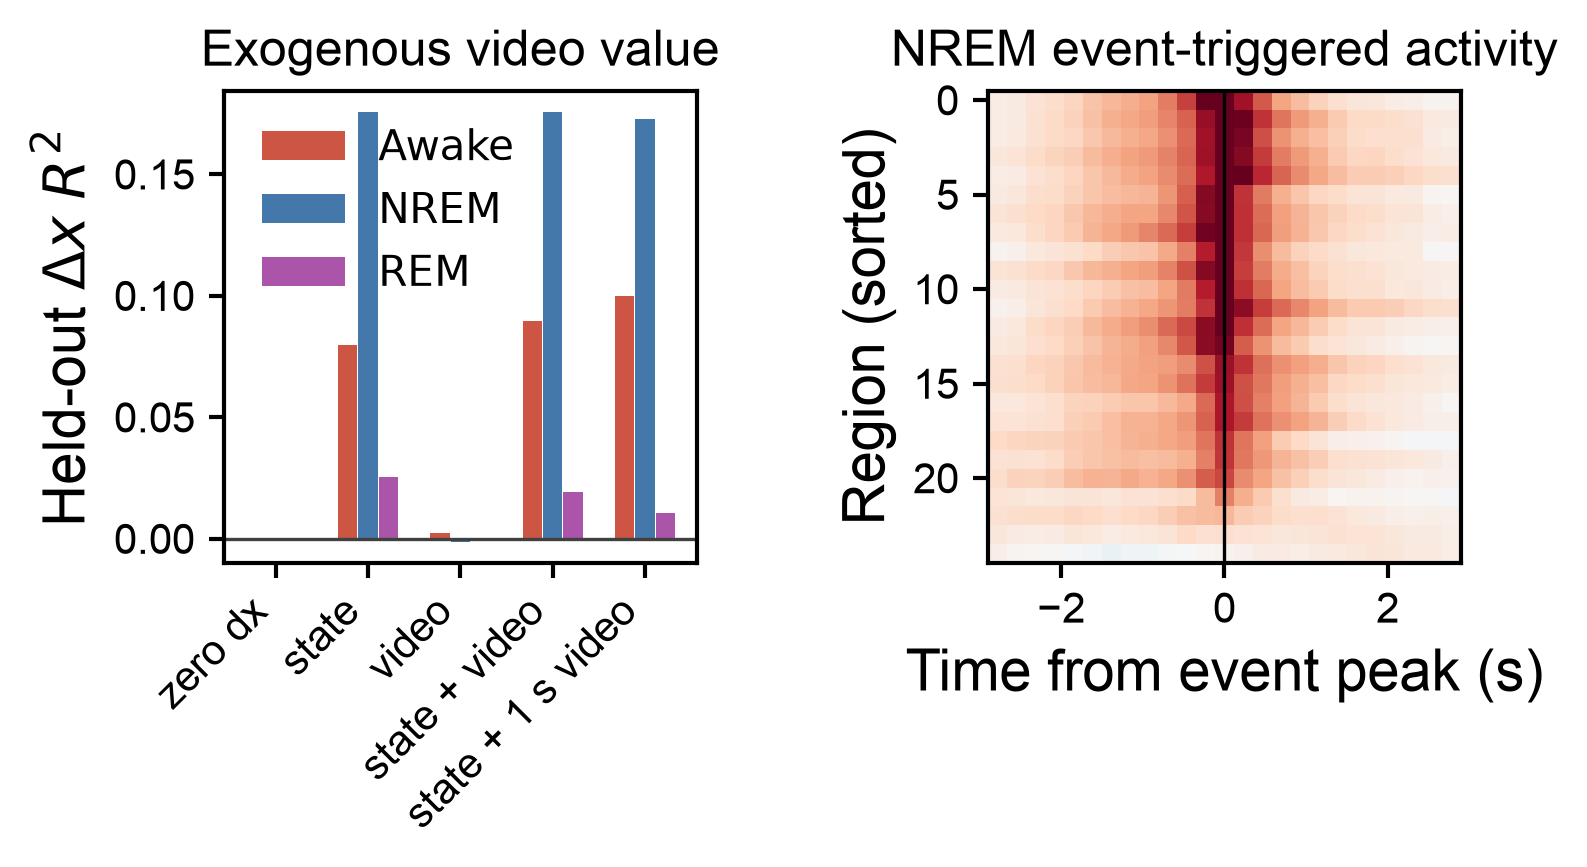

In [7]:
models = ['zero', 'state', 'video', 'state_video', 'state_video_history']
labels = ['zero dx', 'state', 'video', 'state + video', 'state + 1 s video']
colors = {'Awake': '#cc5544', 'NREM': '#4477aa', 'REM': '#aa55aa'}
fig, axes = get_fig(RN=1, CN=2, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
ax = next(ax_loader)
x = np.arange(len(models))
for offset, state in zip([-.22, 0, .22], ['Awake', 'NREM', 'REM']):
    table = video[video.state == state].set_index('model')
    ax.bar(x + offset, table.loc[models].dx_r2_flat, width=.21, color=colors[state], label=state)
ax.axhline(0, color='0.25', lw=.8)
ax.set_xticks(x, labels, rotation=45, ha='right')
ax.set(ylabel=r'Held-out $\Delta x$ $R^2$', title='Exogenous video value')
ax.legend(frameon=False)
ax = next(ax_loader)
template = events['template'].T
offsets = events['offsets_seconds']
regions = events['region_names'].astype(str)
order = np.argsort(template[:, len(offsets)//2])[::-1]
limit = np.quantile(np.abs(template), .98)
ax.imshow(template[order], aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit, extent=[offsets[0], offsets[-1], len(regions)-.5, -.5])
ax.axvline(0, color='black', lw=.8)
ax.set(xlabel='Time from event peak (s)', ylabel='Region (sorted)', title='NREM event-triggered activity')
fig.savefig(OUT / 'video_and_population_events.png', transparent=True)
fig.savefig(OUT / 'video_and_population_events.svg', transparent=True)
fig.savefig(OUT / 'video_and_population_events.pdf', transparent=True)
plt.show()

About one second of video history raises Awake regional increment R² from 0.080 to 0.100. Video alone is weak (0.0025), indicating a modest conditional contribution rather than a replacement for neural state. NREM receives no video benefit, so its strong regional coupling result is not explained by these measured face variables.

NREM event-triggered regional means peak in the same 0.241 s frame. Across 151 events, every regional bootstrap lag interval contains zero. The data support synchronous population events at this resolution, not a reproducible region-level propagation order.